In [4]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import calcium_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/old_hnn_model/'
#os.mkdir(pathfig)

In [3]:
def fig_compartments_new(net, timevec, clamp):
    fig, ax = plt.subplots(2,2, figsize=(8,8), height_ratios=[0.25, 1], sharex=True)

    sections = ['apical_tuft', 'apical_2', 'apical_1', 'apical_trunk','soma']

    ax[0,0].plot(timevec,clamp, color='k')
    ax[0,1].plot(timevec,clamp, color='k')

    ax[0,0].set_ylabel('clamp \n current')
    yticks_v = []
    yticklabels_v = []

    yticks_ca = []
    yticklabels_ca = []

    cv = 0
    cca = 0
    for i,section in enumerate(sections):
        
        v = np.array(net.cell_response.vsec[0][170][section])
        ax[1,0].plot(timevec, v+ cv)
        if section == 'apical_tuft':
            ax[1,0].plot(timevec,np.ones_like(v), color='k', linestyle='-.')

        yticks_v.append(-75+cv)
        yticks_v.append(50+cv)

        yticklabels_v.append(str(np.round(-75)))
        yticklabels_v.append(str(np.round(50)))

        cv -= 200
        ca = np.array(net.cell_response.ca[0][170][section])
        ax[1,1].plot(timevec, ca + cca, label=section)
        


        yticks_ca.append(min(ca)+cca)
        yticks_ca.append(max(ca)+cca)

        yticklabels_ca.append(str(min(ca)))
        yticklabels_ca.append(str(np.round(max(ca),5)))

        cca -= 1


    ax[1,0].set_yticks(yticks_v)
    ax[1,0].set_yticklabels(yticklabels_v)
    ax[1,0].set_ylabel('voltage $\mu V$')
    ax[1,0].set_xlabel('time (ms)')


    ax[1,1].set_yticks(yticks_ca)
    ax[1,1].set_yticklabels(yticklabels_ca)
    ax[1,1].set_ylabel('calcium $mM$')
    ax[1,1].set_xlabel('time (ms)')
    fig.legend(loc='lower right')

    fig.tight_layout()
    return fig


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
lowest ampl t

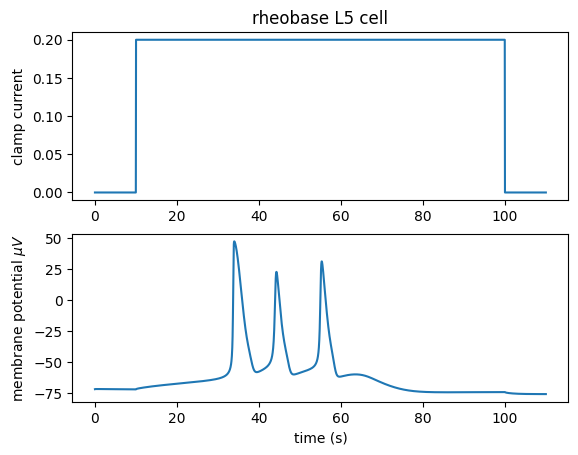

In [15]:
# Jones 2009 rhebase

from scipy.signal import find_peaks
# rheobase L5 pyramidal

ampl = np.arange(0.1,.5,0.05)

for a in ampl:

    net = jones_2009_model(mesh_shape=(1,1))
    net.clear_connectivity()
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='tonic',amplitude=a,t0=10,tstop=100)
    dpl = simulate_dipole(net, tstop=110, n_trials=1,record_vsec='soma')

    v = net.cell_response.vsec[0][3]['soma']

    pk = find_peaks(v, height=0)

    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

t = net.cell_response.times

clamp = np.zeros_like(t) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp)
ax[0].set_ylabel('clamp current')
ax[1].plot(t,v)
ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('membrane potential $\mu V$')
ax[0].set_title('rheobase L5 cell')

fig.savefig(pathfig+'rheobase_L5.png')



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
lowest ampl to induce spike: 0.1


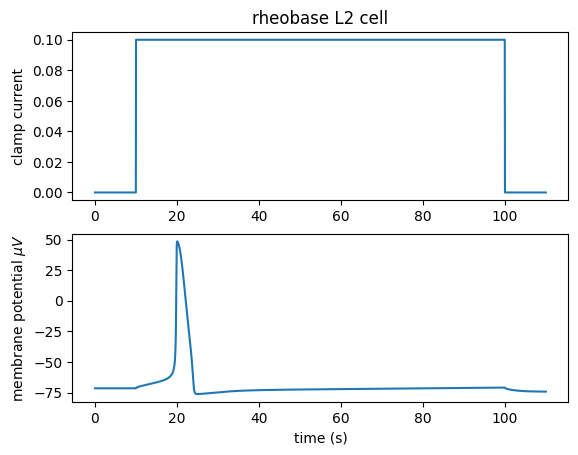

In [22]:
ampl = np.arange(.05,.5,0.05)

for a in ampl:

    net = jones_2009_model(mesh_shape=(1,1))
    net.clear_connectivity()
    net.add_tonic_bias(cell_type='L2_pyramidal',section='soma',bias_name='tonic',amplitude=a,t0=10,tstop=100)
    dpl = simulate_dipole(net, tstop=110, n_trials=1,record_vsec='soma')

    v = net.cell_response.vsec[0][1]['soma']

    pk = find_peaks(v, height=0)

    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

if np.any(pk[0]) == True:
    t = net.cell_response.times

    clamp = np.zeros_like(t) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

    fig, ax = plt.subplots(2,1)

    ax[0].plot(t,clamp)
    ax[0].set_ylabel('clamp current')
    ax[1].plot(t,v)
    ax[1].set_xlabel('time (s)')
    ax[1].set_ylabel('membrane potential $\mu V$')
    ax[0].set_title('rheobase L2 cell')

    fig.savefig(pathfig+'rheobase_L2.png')

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Joblib will r

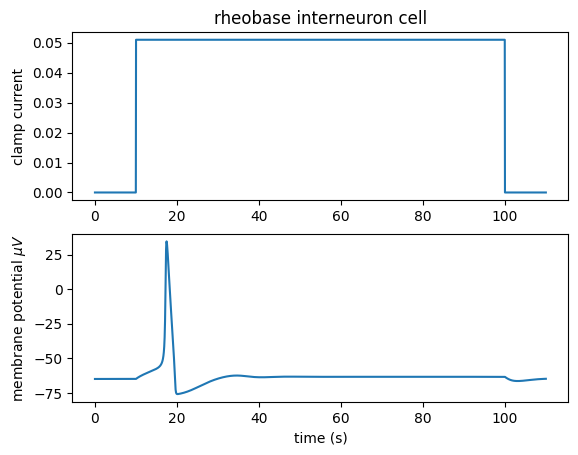

In [24]:
ampl = np.arange(.001,.5,0.001)

for a in ampl:

    net = jones_2009_model(mesh_shape=(1,1))
    net.clear_connectivity()
    net.add_tonic_bias(cell_type='L2_basket',section='soma',bias_name='tonic',amplitude=a,t0=10,tstop=100)
    dpl = simulate_dipole(net, tstop=110, n_trials=1,record_vsec='soma')

    v = net.cell_response.vsec[0][0]['soma']

    pk = find_peaks(v, height=0)

    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

if np.any(pk[0]) == True:
    t = net.cell_response.times

    clamp = np.zeros_like(t) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(t - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

    fig, ax = plt.subplots(2,1)

    ax[0].plot(t,clamp)
    ax[0].set_ylabel('clamp current')
    ax[1].plot(t,v)
    ax[1].set_xlabel('time (s)')
    ax[1].set_ylabel('membrane potential $\mu V$')
    ax[0].set_title('rheobase interneuron cell')

    fig.savefig(pathfig+'rheobase_interneuron.png')

# Old calcium model simulations for comparison to new model

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


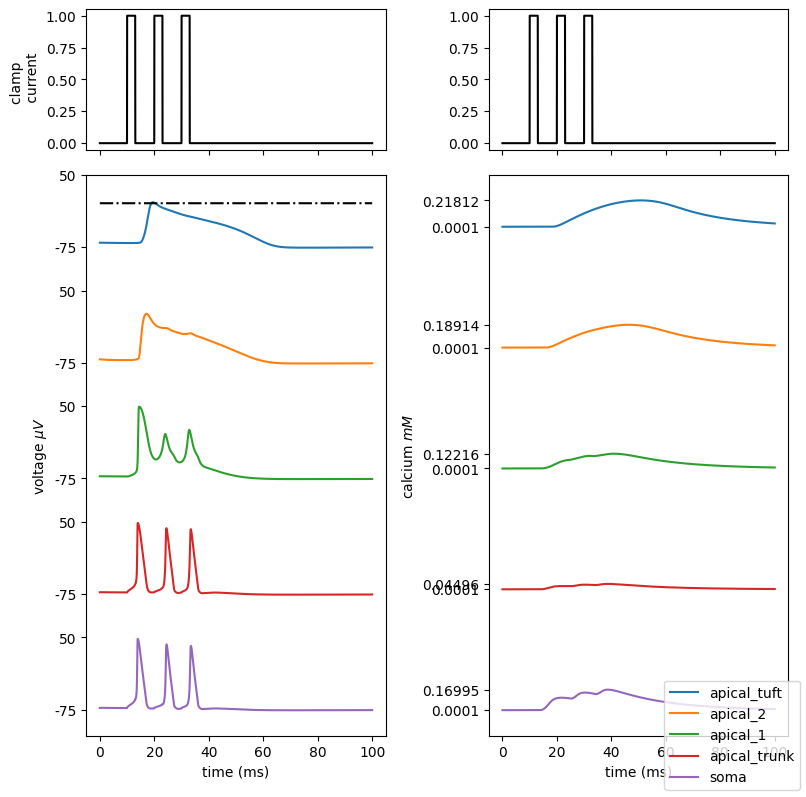

In [29]:
net = calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.
t0 = 10

for i in range(3):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

timevec = net.cell_response.times

fig = fig_compartments_new(net, timevec, clamp)
fig.savefig(os.path.join(pathfig,"crit_freq.png"))


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


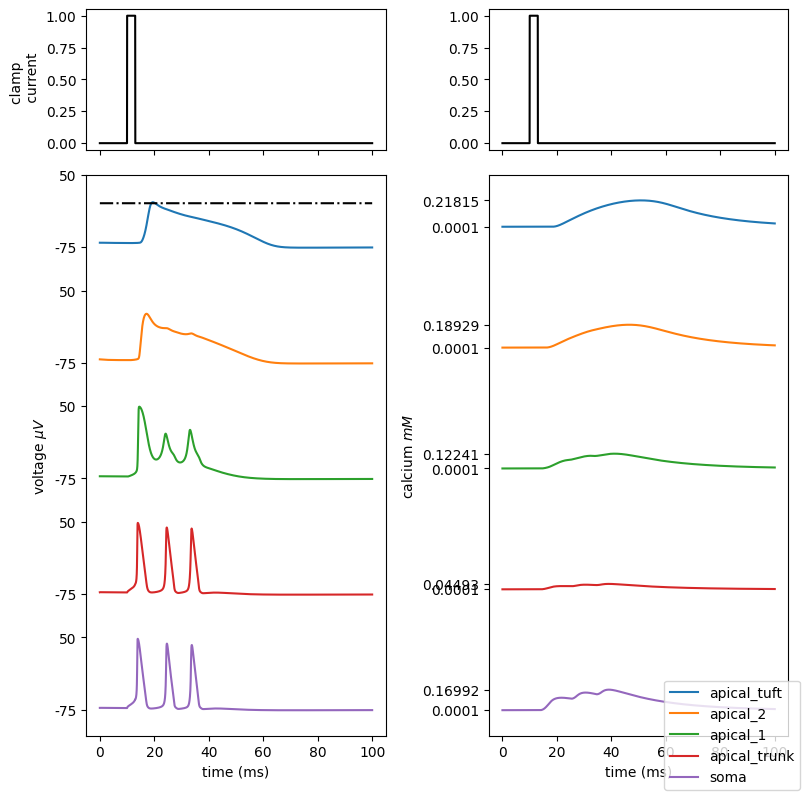

In [30]:
# one pulse 

net = calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.
t0 = 10

for i in range(1):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

timevec = net.cell_response.times

fig = fig_compartments_new(net, timevec, clamp)
fig.savefig(os.path.join(pathfig,"one_pulse.png"))

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


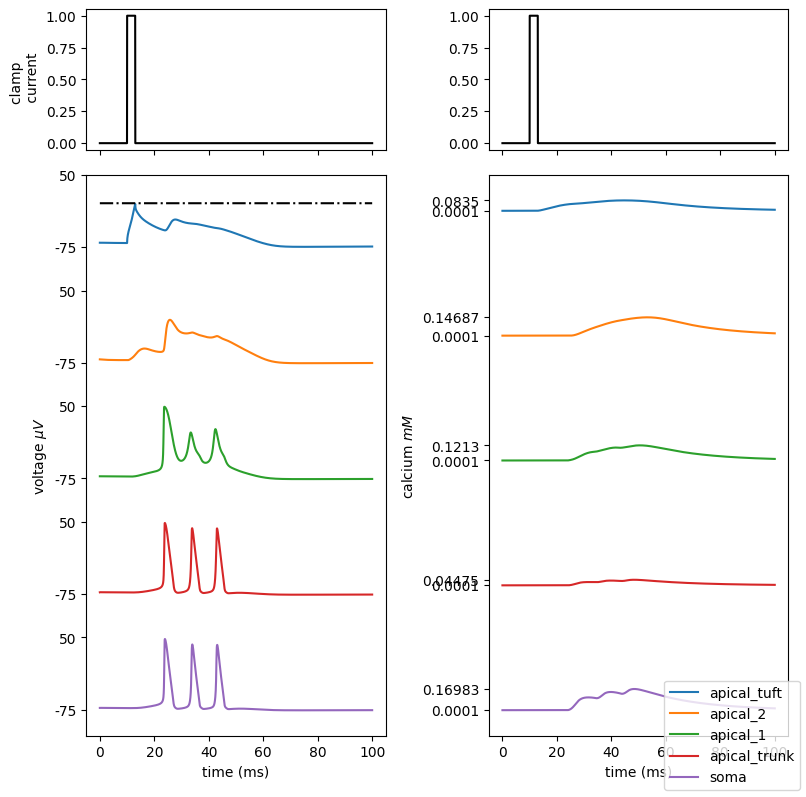

In [31]:
net = calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.
t0 = 10

for i in range(1):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

timevec = net.cell_response.times

fig = fig_compartments_new(net, timevec, clamp)
fig.savefig(os.path.join(pathfig,"distal_drive.png"))

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...


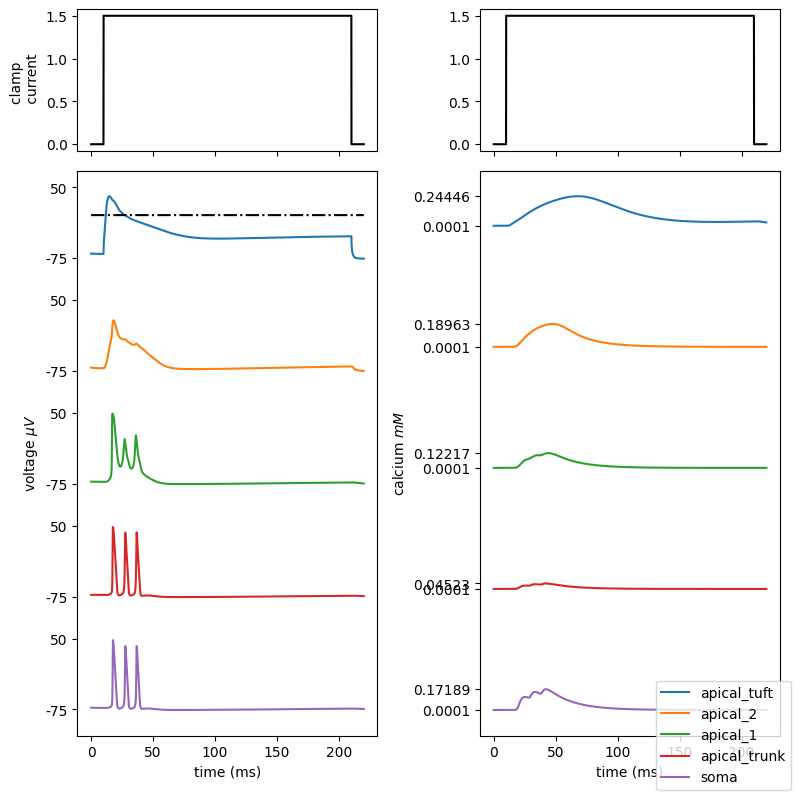

In [33]:
# continuous clamp
net = calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.5
t0 = 10

for i in range(1):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=10,tstop=210)

dpl = simulate_dipole(net, tstop=220, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

timevec = net.cell_response.times

fig = fig_compartments_new(net, timevec, clamp)
fig.savefig(os.path.join(pathfig,"continuous_clamp.png"))

In [5]:
window_len, scaling_factor = 20, 3000
dpl[0].scale(scaling_factor)

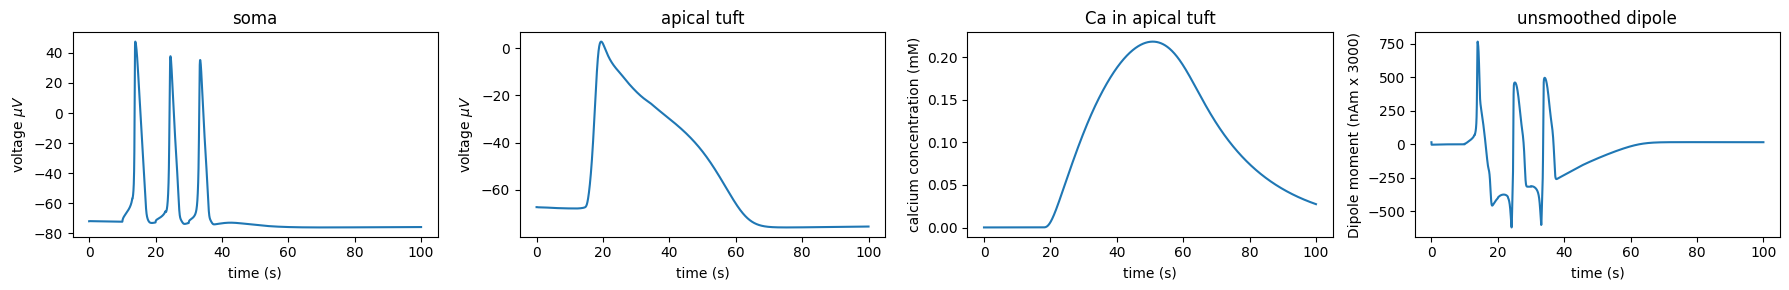

In [ ]:
fig, axs = plt.subplots(1,4,figsize=(18,3))
# v_int2 = net.cell_response.vsec[0][0]['soma']
# plt.plot(timevec, v_int2)
# v_l2 = net.cell_response.vsec[0][35]['soma']
# plt.plot(timevec, v_l2)
# v_int5 = net.cell_response.vsec[0][135]['soma']
# plt.plot(timevec, v_int5)
v_l5 = net.cell_response.vsec[0][170]['soma']
axs[0].plot(timevec, v_l5)
axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')
v_l5_apcl = net.cell_response.vsec[0][170]['apical_tuft']
axs[1].plot(timevec, v_l5_apcl)
axs[1].set_ylabel('voltage $\mu V$')
axs[1].set_title('apical tuft')

ca_l5 = net.cell_response.ca[0][170]['apical_tuft']

axs[2].plot(timevec, ca_l5)
axs[2].set_title('Ca in apical tuft')
axs[2].set_ylabel('calcium concentration (mM)')

axs[3].plot(timevec, dpl[0].data['L5'])
axs[3].set_title('unsmoothed dipole')
axs[3].set_ylabel('Dipole moment (nAm x 3000)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_electrophysio_old_ca.png'))

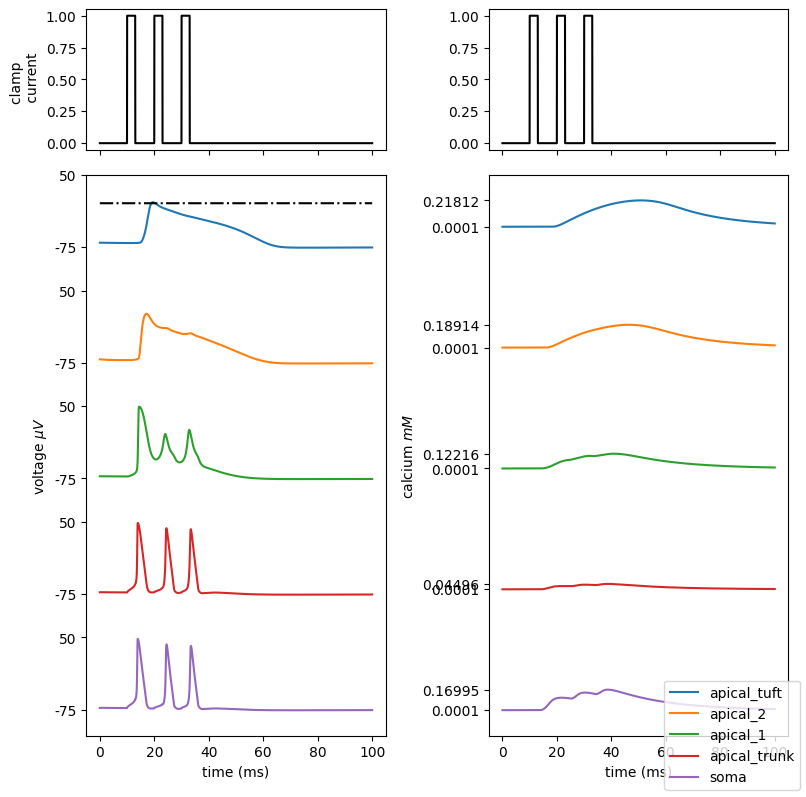

In [7]:
dpl[0].smooth(window_len)

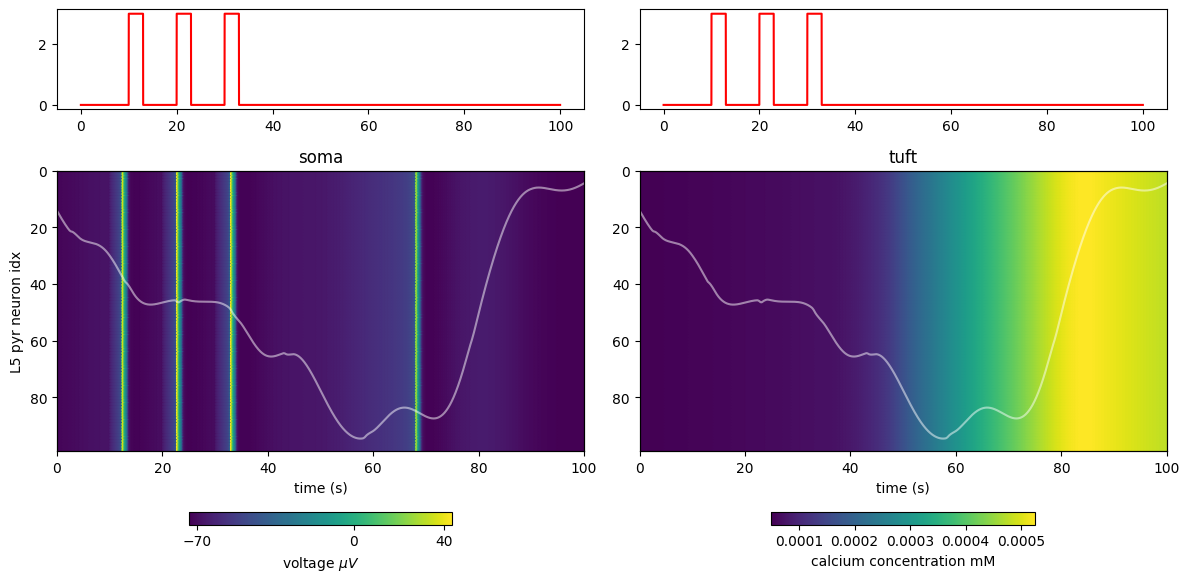

In [21]:

fig, axs = plt.subplots(2,2,figsize=(12,6),height_ratios=[0.25, 1])

axs[0,0].plot(timevec, clamp, color='r')
axs[0,1].plot(timevec, clamp, color='r')

im = axs[1,0].pcolormesh(timevec,np.arange(len(l5_unique_gids)),vltg_l5_soma, shading='gouraud')
axs[1,0].invert_yaxis()
axs[1,0].set_title('soma')
cb = plt.colorbar(im, ax= axs[1,0], orientation='horizontal', shrink=0.5)
cb.set_label('voltage $\mu V$')
cb.set_ticks([-70,0, 40])
ax2 = axs[1,0].twinx()
ax2.plot(timevec,dpl[0].data['agg'], color=(1,1,1), alpha=0.5)
ax2.set_yticks([])

window_len, scaling_factor = 20, 3000

im = axs[1,1].pcolormesh(timevec,np.arange(len(l5_unique_gids)),ca_l5_tuft, shading='gouraud')
axs[1,1].invert_yaxis()
axs[1,1].set_title('tuft')
axs[1,1].set_xlabel('time (s)')
axs[1,0].set_xlabel('time (s)')

axs[1,0].set_ylabel('L5 pyr neuron idx')
cb = plt.colorbar(im, ax= axs[1,1], orientation='horizontal', shrink=0.5)
cb.set_label('calcium concentration mM')
ax2 = axs[1,1].twinx()
ax2.plot(timevec,dpl[0].data['agg'], color=(1,1,1), alpha=0.5)
ax2.set_yticks([])



fig.tight_layout()

fig.savefig(os.path.join(pathfig,'l5_network_rsp.png'))

In [8]:
from hnn_core.extracellular import _get_laminar_z_coords

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


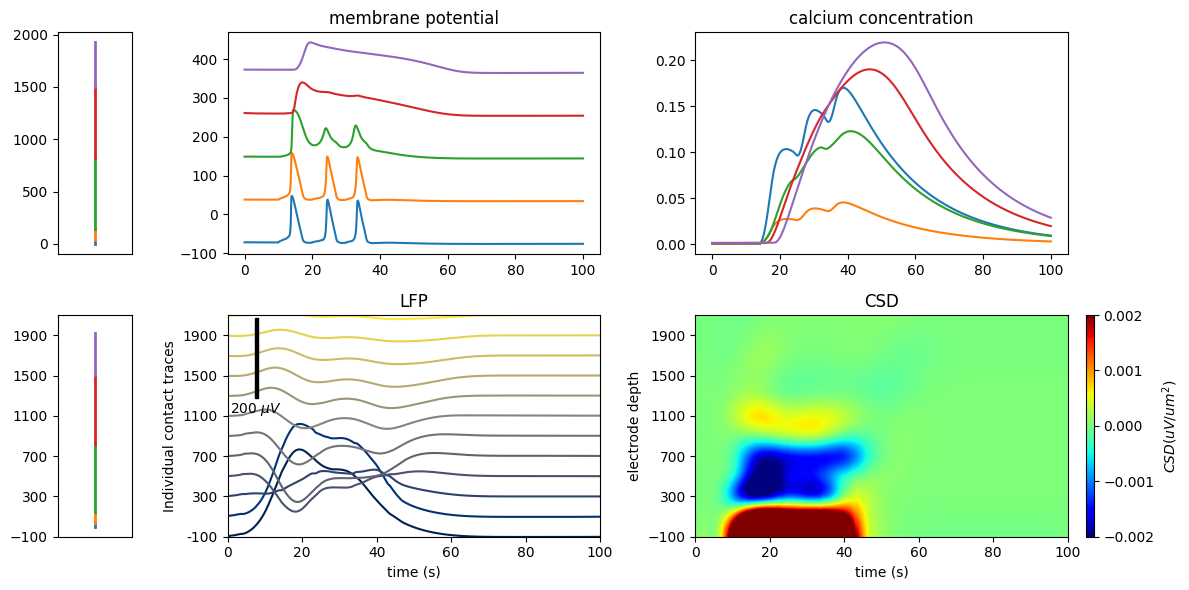

In [34]:
net = calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.
t0 = 10

for i in range(3):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

timevec = net.cell_response.times

fig, axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[0.2, 1, 1])

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[0,1].plot(timevec, v + i*110)
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[0,2].plot(timevec, ca + i*0.0003)
    prevL += L[i]


axs[0,0].set_xticks([])
axs[1,0].set_xticks([])
axs[0,1].set_title('membrane potential')
axs[0,2].set_title('calcium concentration')

new_ticks = contact_labels[0:len(contact_labels):2]
axs[1,0].set_yticks(new_ticks)

net.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,1], show=False)
lfp_ticks = axs[1,1].get_yticks()
lfp_ticks = lfp_ticks[0:-1:2]

axs[1,1].set_yticks(lfp_ticks)
axs[1,1].set_ylim([lfp_ticks[0], lfp_ticks[-1]+50])
axs[1,1].set_xlabel('time (s)')
axs[1,1].set_title('LFP')

net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,2], show=False, vmin=-0.002, vmax=0.002)
axs[1,2].set_yticks(new_ticks)
axs[1,2].set_title('CSD')
axs[1,2].set_ylim((-100, 2100))
axs[1,0].set_ylim(axs[1,2].get_ylim())

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_old_ca.png'))
#fig.savefig(os.path.join(pathfig,'l5_lfp_csd.svg'))



In [36]:
net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs

{'hh2': {'gkbar_hh2': [[0.05555555555555555,
    0.16666666666666666,
    0.2777777777777778,
    0.38888888888888884,
    0.5,
    0.611111111111111,
    0.7222222222222222,
    0.8333333333333333,
    0.9444444444444444],
   [0.0001063880762999082,
    0.00010481193765176169,
    0.0001036246818098861,
    0.00010273035919700855,
    0.00010205669400396924,
    0.00010154924312910825,
    0.00010116699629038498,
    0.00010087906172774587,
    0.00010066216964659985]],
  'gnabar_hh2': [[0.05555555555555555,
    0.16666666666666666,
    0.2777777777777778,
    0.38888888888888884,
    0.5,
    0.611111111111111,
    0.7222222222222222,
    0.8333333333333333,
    0.9444444444444444],
   [0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247,
    0.0028000000000000247]],
  'gl_hh2': 4.26e-05,
  'el_hh2': -71.0},
 'ca': {'gbar_ca': 

In [35]:
net_no_ca = calcium_model()
net_no_ca.clear_connectivity()

# block Ca
# 
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in sections:
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])


net_no_ca.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

for i in range(3):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

window_len, scaling_factor = 20, 3000
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


KeyError: 'Ca_HVA'

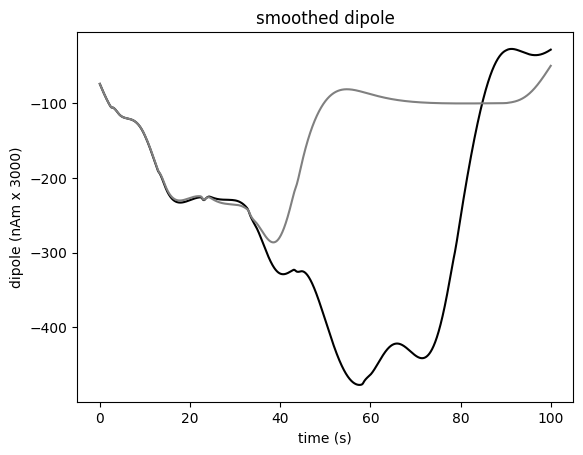

In [12]:
fig, ax = plt.subplots()
ax.plot(timevec, dpl[0].data['L5'], color='k')
ax.plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5])

ax.set_title('smoothed dipole')
ax.set_ylabel('dipole (nAm x 3000)')
ax.set_xlabel('time (s)')
fig.savefig(os.path.join(pathfig,'dipole.png'))


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


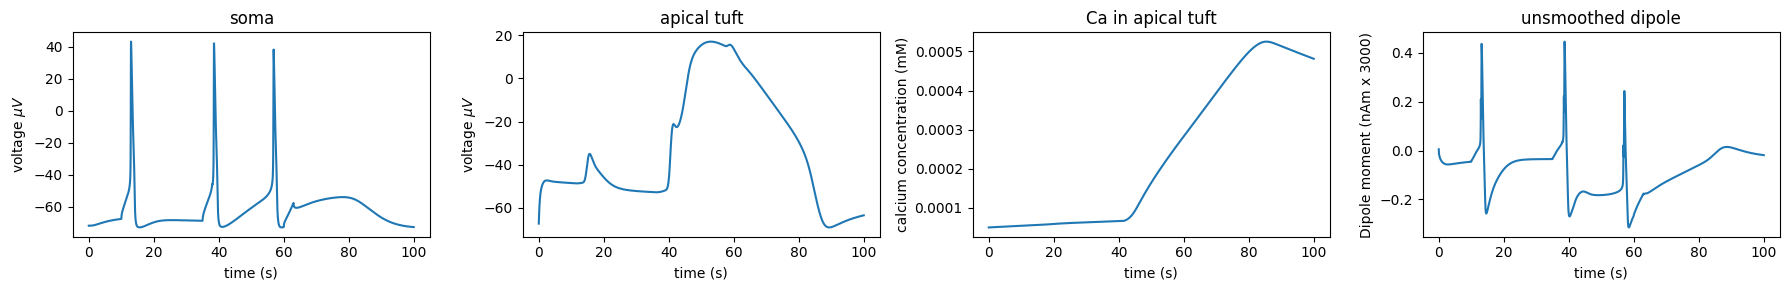

In [13]:
net = new_calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 2.5
t0 = 10

for i in range(3):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*25,tstop=t0+i*25+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

timevec = net.cell_response.times


fig, axs = plt.subplots(1,4,figsize=(18,3))

v_l5 = net.cell_response.vsec[0][170]['soma']
axs[0].plot(timevec, v_l5)
axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')
v_l5_apcl = net.cell_response.vsec[0][170]['apical_tuft']
axs[1].plot(timevec, v_l5_apcl)
axs[1].set_ylabel('voltage $\mu V$')
axs[1].set_title('apical tuft')

ca_l5 = net.cell_response.ca[0][170]['apical_tuft']

axs[2].plot(timevec, ca_l5)
axs[2].set_title('Ca in apical tuft')
axs[2].set_ylabel('calcium concentration (mM)')

axs[3].plot(timevec, dpl[0].data['L5'])
axs[3].set_title('unsmoothed dipole')
axs[3].set_ylabel('Dipole moment (nAm x 3000)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'critfreq.png'))


In [ ]:
# Rhebase Jones 2009

